# 实验二：Matplotlib 绘图实践

**数据集：** 昆明市 2025 年环境监测日值（`kuiming_2025.csv`）  
**实验内容：** 折线图、柱状图、散点图、直方图、饼图、箱线图、标注与统计表、多图组合，以及选做三维曲面图。

本报告按照实验说明完成 T1–T8。每个任务都使用同一份数据，统一设置字体、配色和图表风格。代码单元格可以从头到尾重新运行。

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings('ignore', category=UserWarning)
DATA_PATH = Path('kuiming_2025.csv')
OUT_DIR = Path('figures')
OUT_DIR.mkdir(exist_ok=True)

# 中文字体优先使用微软雅黑/黑体，并关闭负号乱码。
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 180

NAVY = '#1E3A8A'
BLUE = '#3B82F6'
AMBER = '#F59E0B'
RED = '#DC2626'
WEATHER_COLORS = {'晴':'#F59E0B', '多云':'#60A5FA', '阴':'#64748B', '小雨':'#14B8A6', '雷阵雨':'#8B5CF6'}
SEASONS = ['春', '夏', '秋', '冬']
WEATHER_ORDER = ['晴', '多云', '阴', '小雨', '雷阵雨']

df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
df['月份'] = df['月份'].astype(int)
df['天气现象'] = pd.Categorical(df['天气现象'], categories=WEATHER_ORDER, ordered=True)
print(f'数据规模：{df.shape[0]} 行 × {df.shape[1]} 列')
print('缺失值总数：', int(df.isna().sum().sum()))
df.head()

数据规模：365 行 × 11 列
缺失值总数： 0


,日期序号,月份,季节,最高气温,最低气温,平均气温,湿度,降水量,AQI,风速,天气现象
0,1,1,冬,12.0,5.9,9.0,65.6,3.7,82.0,3.6,小雨
1,2,1,冬,17.4,10.4,13.9,45.3,0.0,79.8,3.9,晴
2,3,1,冬,15.8,11.7,13.7,47.9,0.0,98.2,5.6,晴
3,4,1,冬,14.1,6.0,10.0,55.7,0.0,94.3,5.3,晴
4,5,1,冬,10.6,2.5,6.6,56.8,0.0,88.4,5.3,晴


## 数据概览与统计摘要

数据包含日期序号、月份、季节、最高/最低/平均气温、湿度、降水量、AQI、风速和天气现象。先计算后续绘图所需的月度、季节和天气类别统计量。

In [2]:
month = np.arange(1, 13)
monthly = df.groupby('月份', observed=False).agg(
    最高气温=('最高气温', 'mean'),
    最低气温=('最低气温', 'mean'),
    平均降水量=('降水量', 'mean'),
    平均AQI=('AQI', 'mean')
).reindex(month)
season_aqi = [df.loc[df['季节'] == s, 'AQI'].dropna() for s in SEASONS]
weather_counts = df['天气现象'].value_counts().reindex(WEATHER_ORDER, fill_value=0)

summary = pd.DataFrame({
    '指标': ['记录数', 'AQI均值', 'AQI中位数', 'AQI最小值', 'AQI最大值', '最高气温与湿度相关系数'],
    '数值': [len(df), df['AQI'].mean(), df['AQI'].median(), df['AQI'].min(), df['AQI'].max(), df['最高气温'].corr(df['湿度'])]
})
summary.style.format({'数值': lambda x: f'{x:.2f}' if isinstance(x, (float, np.floating)) else x})

,指标,数值
0,记录数,365.00
1,AQI均值,94.36
2,AQI中位数,94.00
3,AQI最小值,20.00
4,AQI最大值,185.20
5,最高气温与湿度相关系数,0.36


## T1：月平均气温走势（折线图）

用双折线比较每月平均最高气温和最低气温。图中加入 0 ℃参考线、图例和网格，便于观察全年季节变化。

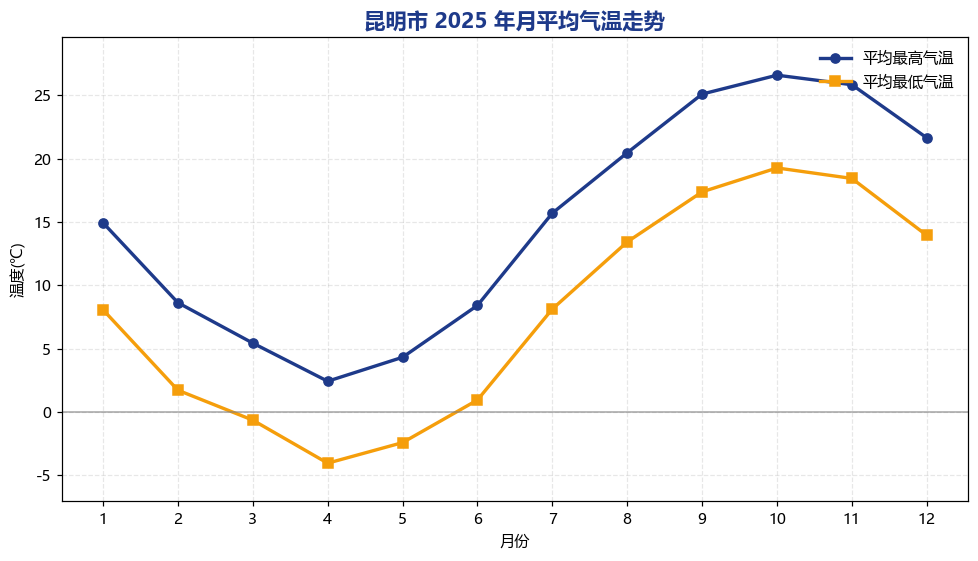

最高气温月均值峰值出现在 10 月，为 26.59 ℃；最低气温月均值最低出现在 4 月，为 -4.03 ℃。


In [3]:
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(month, monthly['最高气温'], marker='o', color=NAVY, linewidth=2.2, markersize=6, label='平均最高气温')
ax.plot(month, monthly['最低气温'], marker='s', color=AMBER, linewidth=2.2, markersize=6, label='平均最低气温')
ax.axhline(0, color='gray', linewidth=1, alpha=0.7)
ax.set_title('昆明市 2025 年月平均气温走势', fontsize=14, fontweight='bold', color=NAVY)
ax.set_xlabel('月份'); ax.set_ylabel('温度(℃)')
ax.set_xticks(month); ax.set_ylim(monthly[['最高气温','最低气温']].min().min()-3, monthly[['最高气温','最低气温']].max().max()+3)
ax.legend(loc='upper right', frameon=False); ax.grid(linestyle='--', alpha=.3)
fig.tight_layout(); fig.savefig(OUT_DIR/'t1_temperature.png', bbox_inches='tight')
plt.show()
print(f"最高气温月均值峰值出现在 {monthly['最高气温'].idxmax()} 月，为 {monthly['最高气温'].max():.2f} ℃；最低气温月均值最低出现在 {monthly['最低气温'].idxmin()} 月，为 {monthly['最低气温'].min():.2f} ℃。")

## T2：各月平均降水量（柱状图）

柱状图直接比较各月平均降水量，并在柱顶显示数值。数据中 7–9 月的降水量明显高于 3–6 月，符合昆明夏季雨季特征。

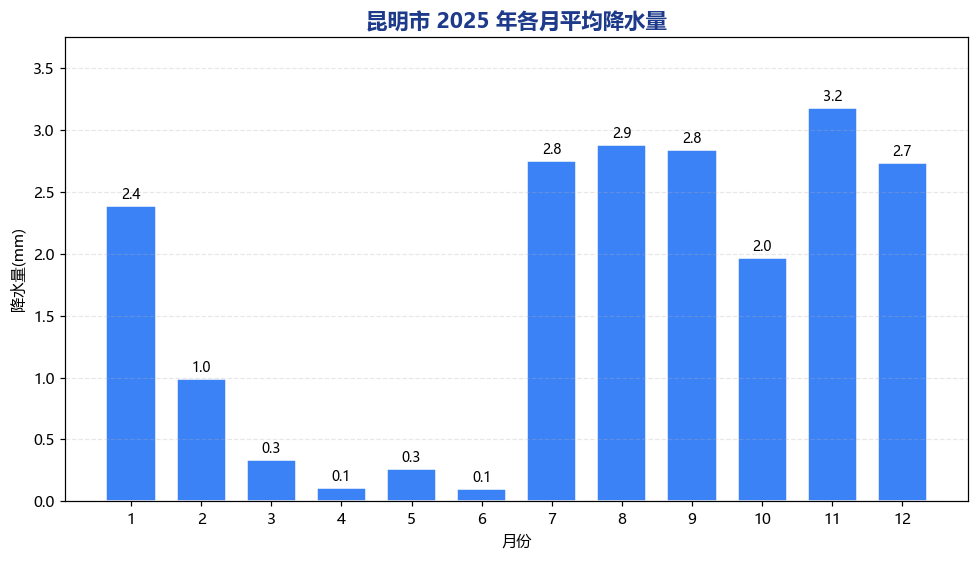

平均降水量最高为 11 月（3.18 mm），最低为 6 月（0.10 mm）。


In [4]:
fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.bar(month, monthly['平均降水量'], width=.7, color=BLUE, edgecolor='white', linewidth=1)
ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=9)
ax.set_title('昆明市 2025 年各月平均降水量', fontsize=14, fontweight='bold', color=NAVY)
ax.set_xlabel('月份'); ax.set_ylabel('降水量(mm)'); ax.set_xticks(month); ax.set_ylim(0, monthly['平均降水量'].max()*1.18)
ax.grid(axis='y', linestyle='--', alpha=.3); fig.tight_layout(); fig.savefig(OUT_DIR/'t2_rainfall.png', bbox_inches='tight')
plt.show()
wettest = monthly['平均降水量'].idxmax(); driest = monthly['平均降水量'].idxmin()
print(f'平均降水量最高为 {wettest} 月（{monthly.loc[wettest, "平均降水量"]:.2f} mm），最低为 {driest} 月（{monthly.loc[driest, "平均降水量"]:.2f} mm）。')

## T3：气温—湿度关系（散点图）

按天气现象着色，观察最高气温与湿度的关系。相关系数用于辅助判断整体线性关系，但不能代替散点图对不同天气类别的观察。

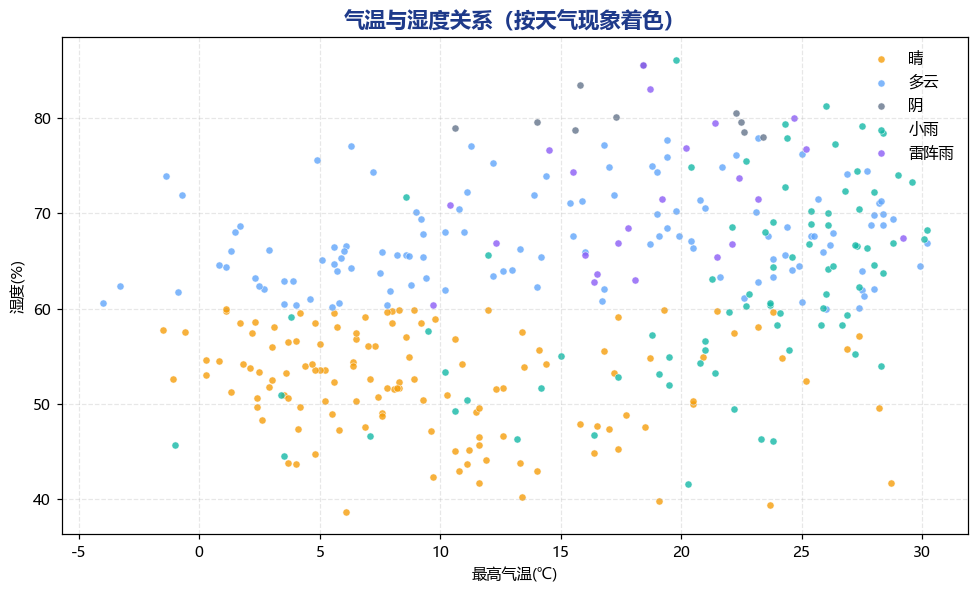

最高气温与湿度的 Pearson 相关系数为 0.356，呈弱到中等正相关；不同天气现象的点云仍存在明显重叠。


In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for w in WEATHER_ORDER:
    part = df[df['天气现象'] == w]
    ax.scatter(part['最高气温'], part['湿度'], s=22, alpha=.8, c=WEATHER_COLORS[w], edgecolors='white', linewidth=.4, label=w)
ax.set_title('气温与湿度关系（按天气现象着色）', fontsize=14, fontweight='bold', color=NAVY)
ax.set_xlabel('最高气温(℃)'); ax.set_ylabel('湿度(%)'); ax.legend(frameon=False, loc='upper right')
ax.grid(linestyle='--', alpha=.3); fig.tight_layout(); fig.savefig(OUT_DIR/'t3_temperature_humidity.png', bbox_inches='tight')
plt.show()
print(f"最高气温与湿度的 Pearson 相关系数为 {df['最高气温'].corr(df['湿度']):.3f}，呈弱到中等正相关；不同天气现象的点云仍存在明显重叠。")

## T4：日 AQI 分布与天气占比

直方图展示 AQI 的数值分布形态，饼图展示不同天气现象在全年记录中的构成比例。两张图回答的问题不同，组合使用可以同时看到“数值如何分布”和“类别如何构成”。

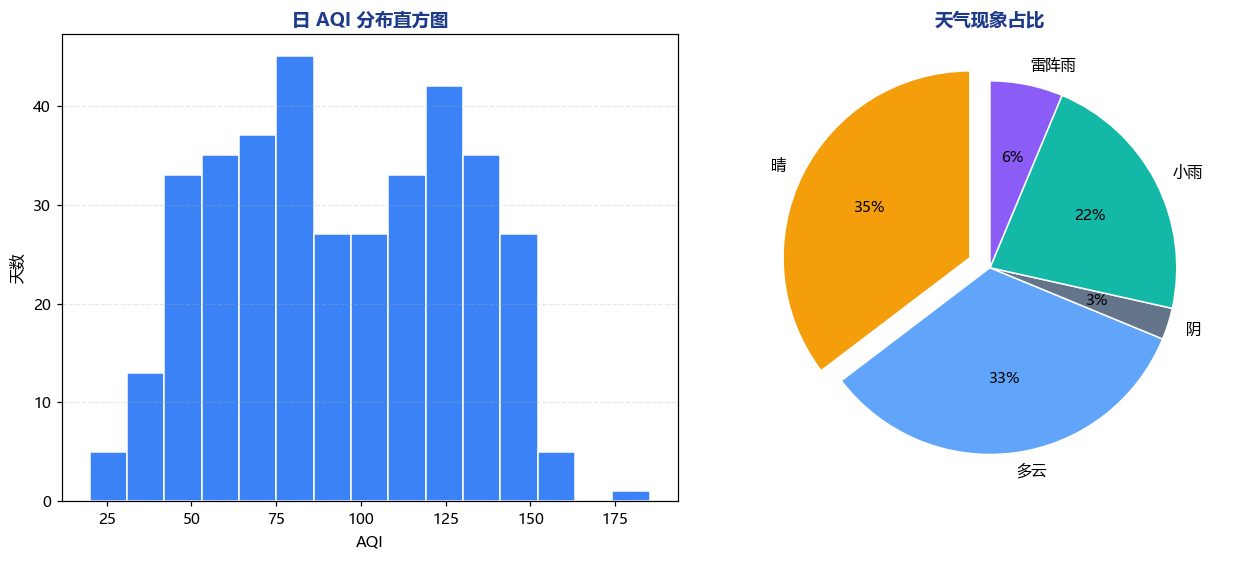

天气现象天数： {'晴': 129, '多云': 122, '阴': 10, '小雨': 81, '雷阵雨': 23}


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2))
ax1.hist(df['AQI'], bins=15, color=BLUE, edgecolor='white', linewidth=1)
ax1.set_title('日 AQI 分布直方图', fontweight='bold', color=NAVY)
ax1.set_xlabel('AQI'); ax1.set_ylabel('天数'); ax1.grid(axis='y', linestyle='--', alpha=.3)
vals = weather_counts.values
colors = [WEATHER_COLORS[w] for w in WEATHER_ORDER]
ax2.pie(vals, labels=WEATHER_ORDER, colors=colors, autopct='%1.0f%%', startangle=90, explode=[.12, 0, 0, 0, 0], wedgeprops={'edgecolor':'white'})
ax2.set_title('天气现象占比', fontweight='bold', color=NAVY)
fig.tight_layout(); fig.savefig(OUT_DIR/'t4_aqi_weather.png', bbox_inches='tight')
plt.show()
print('天气现象天数：', weather_counts.to_dict())

## T5：各季 AQI 分布（箱线图）

箱线图同时给出中位数、四分位距和离群点。春季 AQI 的中心位置最高，秋季最低；箱体高度还可以比较不同季节的波动范围。

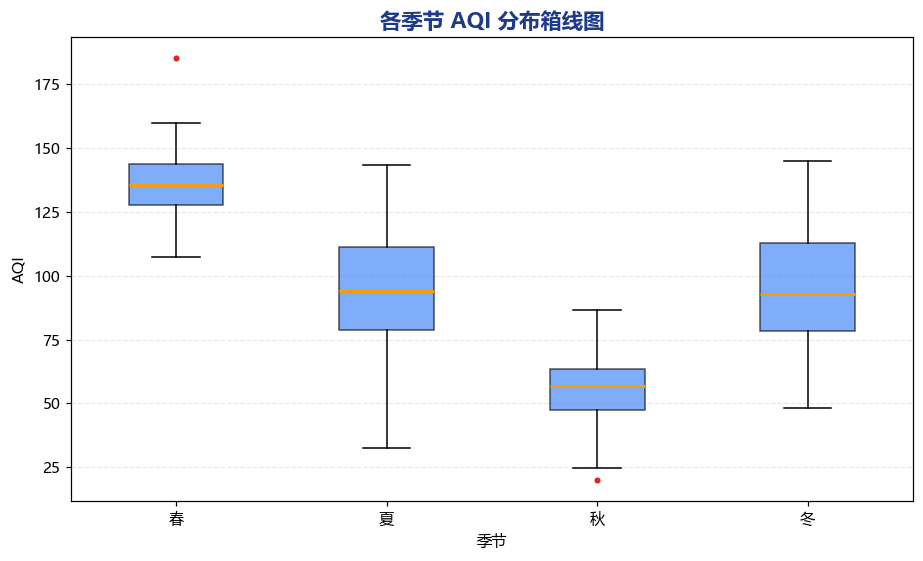

      mean  median    std
季节                       
春   135.69  135.45  11.97
夏    92.78   94.05  22.86
秋    55.36   56.80  13.51
冬    93.63   93.00  22.31


In [7]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
try:
    bp = ax.boxplot(season_aqi, tick_labels=SEASONS, patch_artist=True,
                    medianprops={'color': AMBER, 'linewidth': 2},
                    flierprops={'marker':'o', 'markerfacecolor':RED, 'markersize':4, 'markeredgecolor':'none'})
except TypeError:
    bp = ax.boxplot(season_aqi, labels=SEASONS, patch_artist=True,
                    medianprops={'color': AMBER, 'linewidth': 2},
                    flierprops={'marker':'o', 'markerfacecolor':RED, 'markersize':4, 'markeredgecolor':'none'})
for patch in bp['boxes']:
    patch.set_facecolor(BLUE); patch.set_alpha(.65)
ax.set_title('各季节 AQI 分布箱线图', fontsize=14, fontweight='bold', color=NAVY)
ax.set_xlabel('季节'); ax.set_ylabel('AQI'); ax.grid(axis='y', linestyle='--', alpha=.3)
fig.tight_layout(); fig.savefig(OUT_DIR/'t5_season_aqi_boxplot.png', bbox_inches='tight')
plt.show()
season_stats = df.groupby('季节', observed=False)['AQI'].agg(['mean','median','std']).reindex(SEASONS)
print(season_stats.round(2).to_string())

## T6：最热月标注与季节统计表

在月平均最高气温折线图上标注最高点，并嵌入春、夏、秋、冬四季的平均最高气温统计表，练习 `annotate` 和 `table` 的使用。

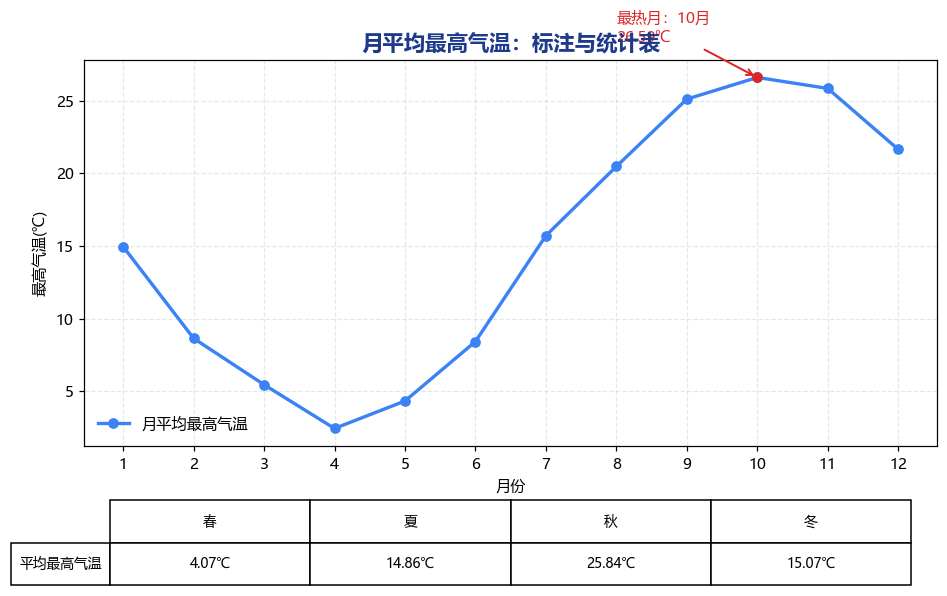

In [8]:
season_high = df.groupby('季节', observed=False)['最高气温'].mean().reindex(SEASONS)
max_month = int(monthly['最高气温'].idxmax()); max_value = float(monthly['最高气温'].max())
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(month, monthly['最高气温'], marker='o', color=BLUE, linewidth=2.2, label='月平均最高气温')
ax.scatter([max_month], [max_value], color=RED, zorder=3)
ax.annotate(f'最热月：{max_month}月\n{max_value:.2f}℃', xy=(max_month, max_value), xytext=(max_month-2.0, max_value+2.5),
            arrowprops=dict(arrowstyle='->', color=RED, linewidth=1.3), color=RED, fontsize=10)
ax.set_title('月平均最高气温：标注与统计表', fontsize=14, fontweight='bold', color=NAVY)
ax.set_xlabel('月份'); ax.set_ylabel('最高气温(℃)'); ax.set_xticks(month); ax.legend(frameon=False, loc='lower left'); ax.grid(linestyle='--', alpha=.3)
table = ax.table(cellText=[[f'{season_high[s]:.2f}℃' for s in SEASONS]], rowLabels=['平均最高气温'], colLabels=SEASONS, cellLoc='center', rowLoc='center', bbox=[0.03, -0.36, .94, .22])
table.auto_set_font_size(False); table.set_fontsize(9)
fig.subplots_adjust(bottom=.34); fig.savefig(OUT_DIR/'t6_annotation_table.png', bbox_inches='tight')
plt.show()

## T7：多图表组合（subplots 2×2）

将月均气温、月均降水、气温湿度散点和日 AQI 直方图放在同一画布中。统一使用前面定义的字体、颜色、标题和网格风格，方便从同一数据背景下进行对照。

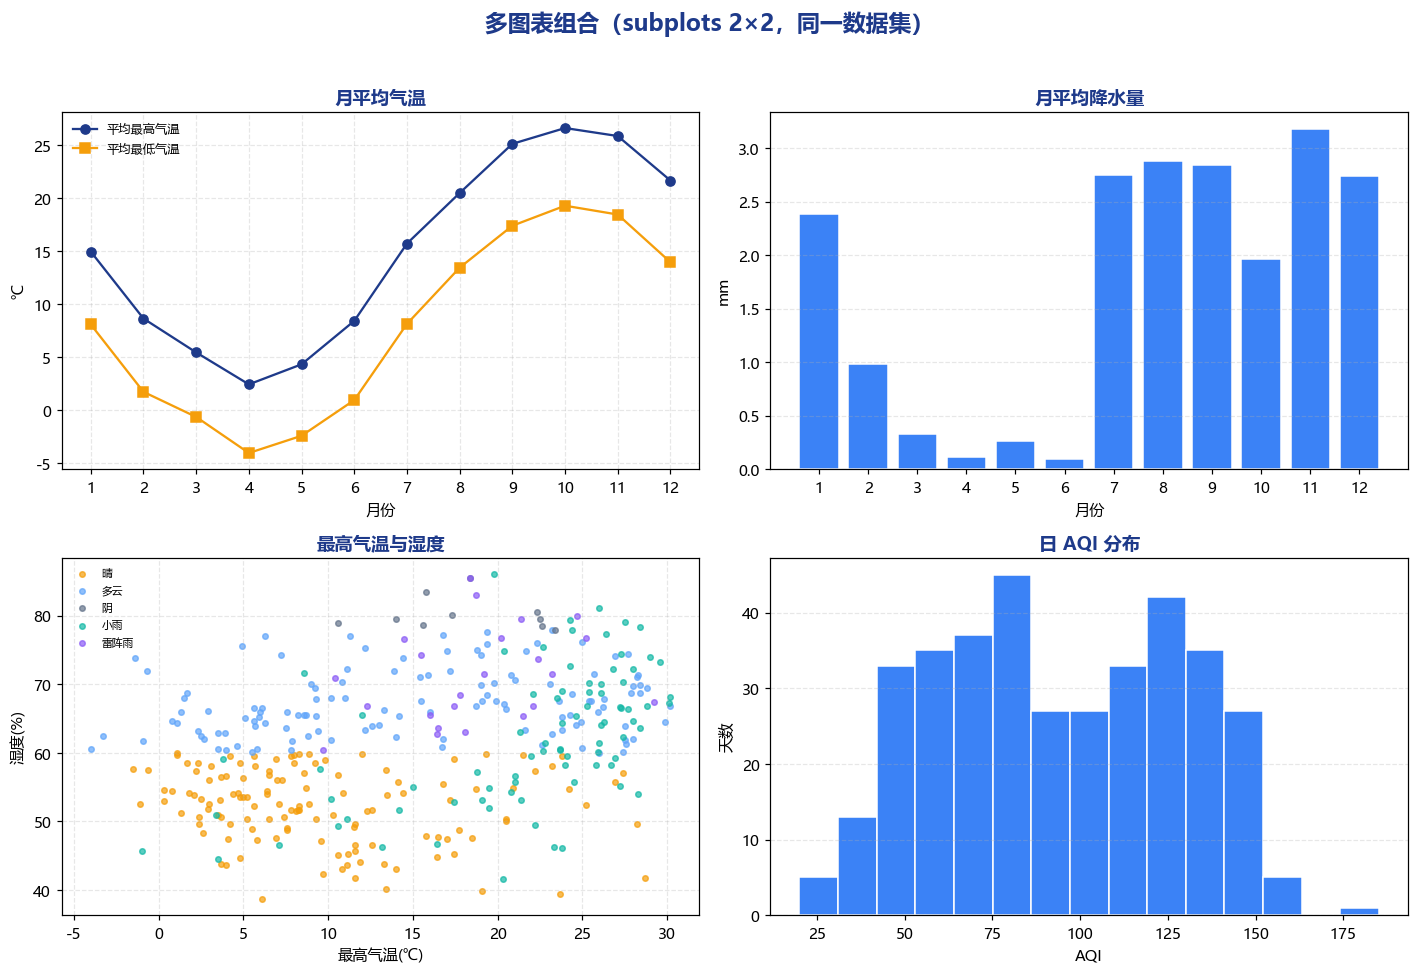

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
ax = axs[0, 0]
ax.plot(month, monthly['最高气温'], marker='o', color=NAVY, label='平均最高气温')
ax.plot(month, monthly['最低气温'], marker='s', color=AMBER, label='平均最低气温')
ax.set_title('月平均气温', fontweight='bold', color=NAVY); ax.set_xlabel('月份'); ax.set_ylabel('℃'); ax.set_xticks(month); ax.legend(frameon=False, fontsize=8); ax.grid(linestyle='--', alpha=.3)
ax = axs[0, 1]
bars = ax.bar(month, monthly['平均降水量'], color=BLUE, edgecolor='white'); ax.set_title('月平均降水量', fontweight='bold', color=NAVY); ax.set_xlabel('月份'); ax.set_ylabel('mm'); ax.set_xticks(month); ax.grid(axis='y', linestyle='--', alpha=.3)
ax = axs[1, 0]
for w in WEATHER_ORDER:
    part = df[df['天气现象'] == w]; ax.scatter(part['最高气温'], part['湿度'], s=13, alpha=.7, color=WEATHER_COLORS[w], label=w)
ax.set_title('最高气温与湿度', fontweight='bold', color=NAVY); ax.set_xlabel('最高气温(℃)'); ax.set_ylabel('湿度(%)'); ax.legend(frameon=False, fontsize=7); ax.grid(linestyle='--', alpha=.3)
ax = axs[1, 1]
ax.hist(df['AQI'], bins=15, color=BLUE, edgecolor='white'); ax.set_title('日 AQI 分布', fontweight='bold', color=NAVY); ax.set_xlabel('AQI'); ax.set_ylabel('天数'); ax.grid(axis='y', linestyle='--', alpha=.3)
fig.suptitle('多图表组合（subplots 2×2，同一数据集）', fontsize=15, fontweight='bold', color=NAVY)
fig.tight_layout(rect=[0, 0, 1, .96]); fig.savefig(OUT_DIR/'t7_subplots.png', bbox_inches='tight')
plt.show()

## T8（选做）：月 × 旬平均最高气温三维曲面

根据每个月内部的日期序号构造上旬、中旬、下旬，再聚合每个“月份 × 旬”的平均最高气温。曲面高度表示平均最高气温，颜色表示数值变化。

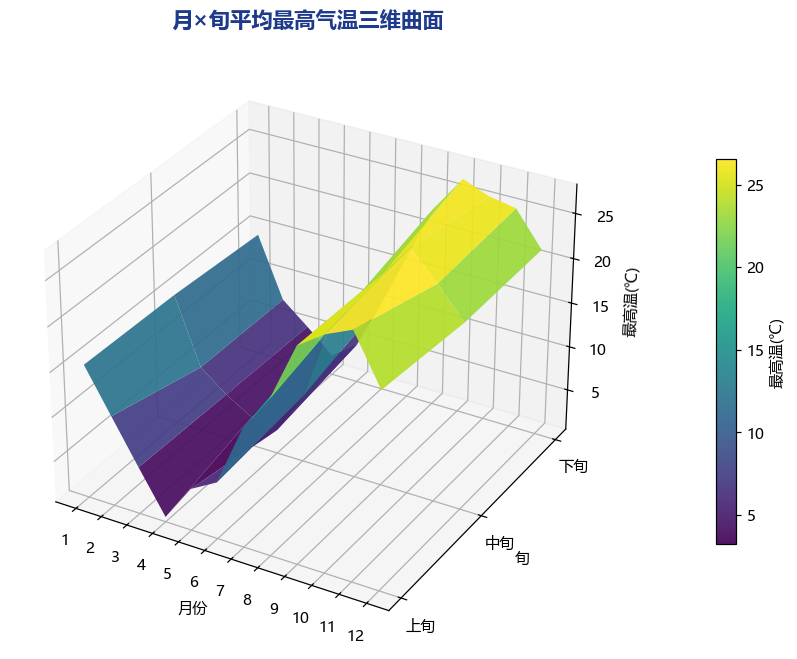

In [10]:
# 每个月内重新编号得到日序，再按 1–10、11–20、21–月底划分为三旬。
df['月内日序'] = df.groupby('月份', observed=False).cumcount() + 1
df['旬'] = ((df['月内日序'] - 1) // 10 + 1).clip(upper=3)
pivot = df.pivot_table(index='旬', columns='月份', values='最高气温', aggfunc='mean', observed=False).reindex(index=[1,2,3], columns=month)
X, Y = np.meshgrid(month, [1, 2, 3])
Z = pivot.to_numpy()
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, Z, cmap='viridis', alpha=.92, edgecolor='none')
ax.set_title('月×旬平均最高气温三维曲面', fontsize=14, fontweight='bold', color=NAVY, pad=18)
ax.set_xlabel('月份'); ax.set_ylabel('旬'); ax.set_zlabel('最高温(℃)')
ax.set_yticks([1,2,3]); ax.set_yticklabels(['上旬','中旬','下旬']); ax.set_xticks(month)
fig.colorbar(surf, ax=ax, shrink=.65, pad=.12, label='最高温(℃)')
fig.tight_layout(); fig.savefig(OUT_DIR/'t8_surface_3d.png', bbox_inches='tight')
plt.show()

## 实验结果分析

- **气温趋势：** 月平均最高气温从春季的低值逐渐升高，在 10 月达到全年峰值，随后回落；月平均最低气温的变化方向与最高气温基本一致。
- **降水变化：** 7–9 月平均降水量相对较高，3–6 月较低，说明降水季节性明显，也与小雨、雷阵雨等天气记录相互印证。
- **气温与湿度：** 最高气温与湿度的相关系数约为 0.356，整体呈弱到中等正相关，但散点分布较分散，天气现象类别之间存在重叠。
- **AQI 季节差异：** 春季 AQI 中心位置最高，秋季最低；箱线图还显示各季节的离散程度和离群点，单看均值无法完整表达这些信息。
- **图表选择：** 折线图适合时间趋势，柱状图适合类别或月份比较，散点图适合两个连续变量的关系，直方图适合数值分布，饼图适合构成比例，箱线图适合比较多组分布的位置、波动和异常值。

## 思考题

### 1. 如何用一份数据同时画出折线、柱状、散点、直方、饼、箱线？

先用 `pandas` 对同一数据集完成分组、计数和筛选，再分别调用 `plot`、`bar`、`scatter`、`hist`、`pie` 和 `boxplot`。每种图表只改变展示方式，底层数据仍来自同一份 DataFrame；通过 `subplots` 可以把多个 Axes 放在一个画布中。

### 2. 多子图怎样做到配色与字体风格统一？

在绘图前集中设置 `plt.rcParams`，统一中文字体和负号显示；再定义一组全局颜色常量和天气现象颜色映射，所有子图重复使用这些设置。标题字号、加粗方式、网格线型、透明度也应集中约定，最后用 `tight_layout` 或 `constrained_layout` 调整间距。

### 3. 何时选用箱线图而非直方图？

需要比较多个组的中位数、四分位距和离群点时选箱线图，例如本实验的四季 AQI；需要了解单个变量的整体频数分布、偏态和峰值位置时选直方图。两者也可以同时使用，以兼顾分布形状和组间比较。